# 01 — Dataset Audit & EDA

**Read-only.** No dataset file is modified by this notebook. Synthesizes the
completed P0 diagnostics (`reports/p0_diagnostics/`) and adds new exploratory
charts feeding the V2 training decisions in notebooks 02-04.

## 1. What the P0 diagnostics already established (summarized, not recomputed)

Full evidence/commands: `reports/p0_diagnostics/README.md`,
`test_label_provenance.md`, `error_cause_analysis.md`.

- **4,260/10,000 image/annotation match rate**: a structural BDD100K packaging
  fact, not a bug. The pipeline sources *images* from the small '10K images'
  package (7,000/1,000/2,000 train/val/test) but *labels* from the full '100K'
  detection-label package (70,000/10,000/20,000) -- two separately-sampled,
  only-partially-overlapping BDD100K releases. `images/10k/val` has 0 label
  matches, so the delivered `val` split was carved from the matched `train`-image
  pool, not BDD100K's official val images.
- **Video-level leakage: checked, not present.** Zero overlapping
  filename-prefix (video-id) groups across every train/val/test pair, confirmed
  both by direct recomputation and against BDD100K's documented filename format.
- **Test-label provenance: resolved.** `labels/100k/test`'s 20,000 real
  annotation files are genuine BDD100K data from the *original 2018 release*
  (archive-extraction timestamps, zero stem-overlap with train/val, matching
  weather/timeofday distributions) -- just not equivalent to BDD100K's modern
  held-out leaderboard test set, since that policy postdates this release.

In [1]:
import pandas as pd

from pathlib import Path

from IPython.display import Image, display



DA = Path('../../reports/drivesight_v2/dataset_audit')

counts = pd.read_csv(DA / 'class_instance_counts.csv')

piv = counts.pivot(index='class', columns='split', values='instances')

CLASS_ORDER = ['pedestrian','rider','car','truck','bus','motorcycle','bicycle','traffic light','traffic sign']

display(piv.reindex(CLASS_ORDER)[['train','val','test']])

split          train   val  test
class                           
pedestrian      4678  1083  1228
rider            245    59    72
car            29725  7401  9228
truck           1555   356   474
bus              571   151   171
motorcycle       166    45    39
bicycle          399    74   116
traffic light   6820  1759  2159
traffic sign   10044  2492  3027

car:rider train ratio = 121.3:1

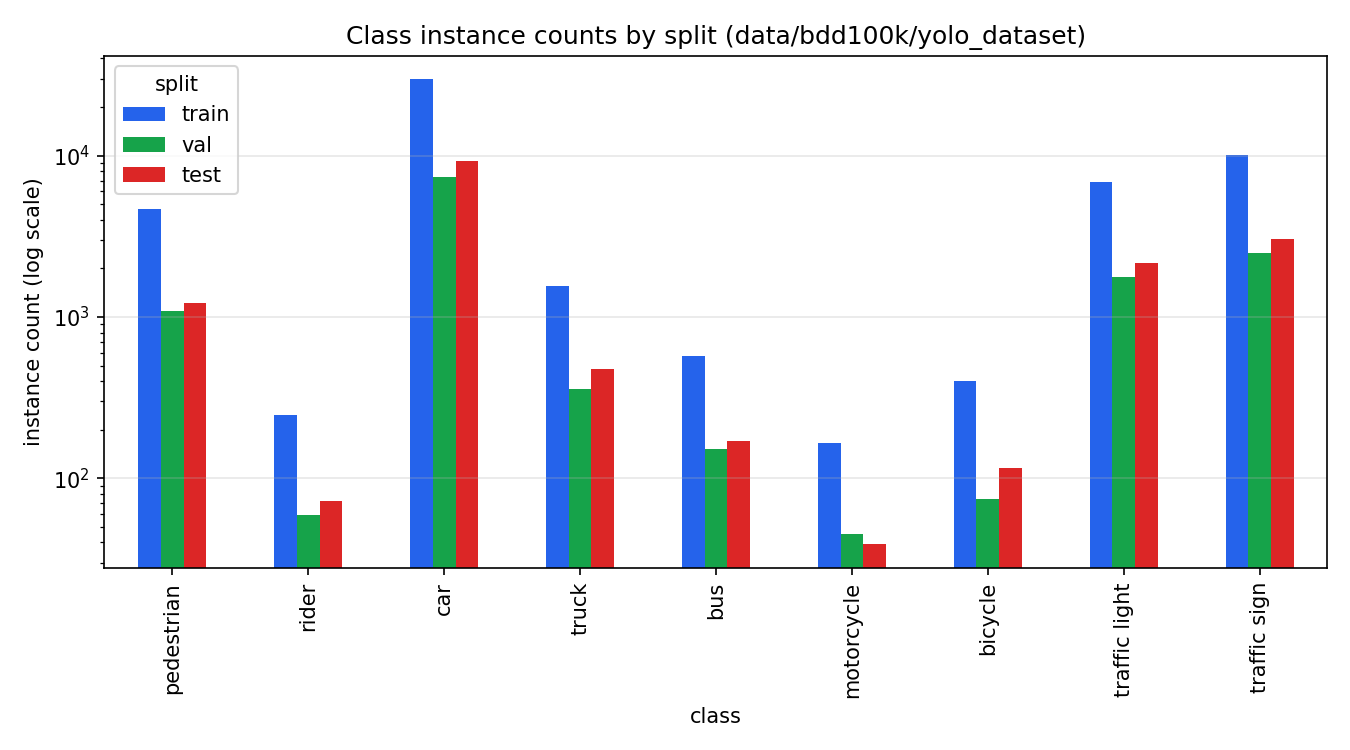

In [1]:
display(Image(filename=str(DA / 'class_instance_counts.png')))

## 2. Class imbalance is severe and consistent across all three splits

car:rider ratio is ~121:1 in train (and proportionally similar in val/test) --
this is the dominant, already-quantified driver of the rare-class AP ceiling from
the P0 pass. `cls_pw` (verified real per-class inverse-frequency loss weighting,
see `train_v2.py`) targets exactly this number directly from training labels.

In [1]:
sizes = pd.read_csv(DA / 'box_size_distribution_train.csv')

display(sizes.groupby('class')['norm_area_pct'].median().reindex(CLASS_ORDER).rename('median_box_area_pct'))

class
pedestrian       0.109
rider            0.161
car              0.141
truck            0.600
bus              0.668
motorcycle       0.293
bicycle          0.230
traffic light    0.030
traffic sign     0.049

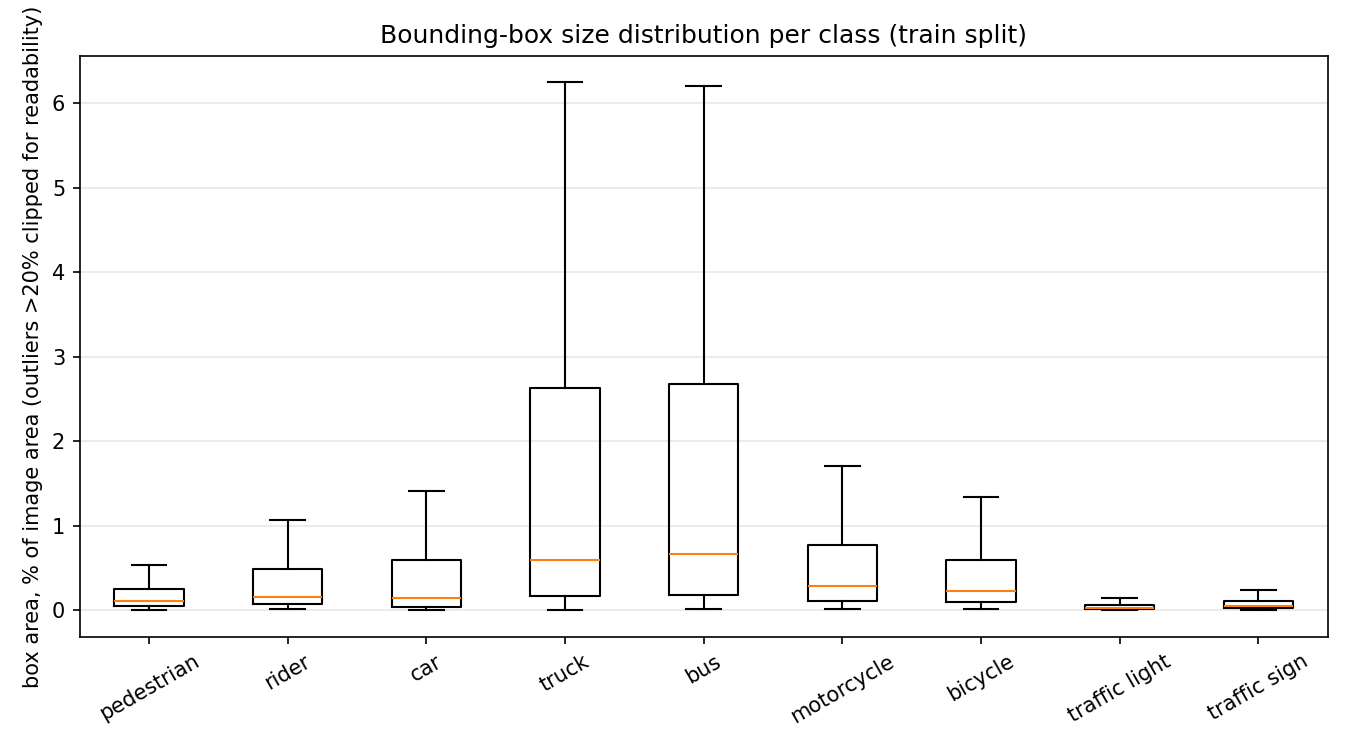

In [1]:
display(Image(filename=str(DA / 'box_size_distribution.png')))

## 3. Box size does NOT explain the rare-class gap by itself

Rider/motorcycle median box area is *larger* than car's, not smaller --
confirming the earlier P0 finding that traffic-light/sign (genuinely tiny) and
rider/motorcycle/bicycle (data-scarce, not small) are two **distinct** failure
regimes requiring different fixes (resolution helps the former; data/loss-
weighting the latter). The resolution-ablation notebook separately confirmed a
*universal* small-object recall gap that hits even `car`, on top of this.

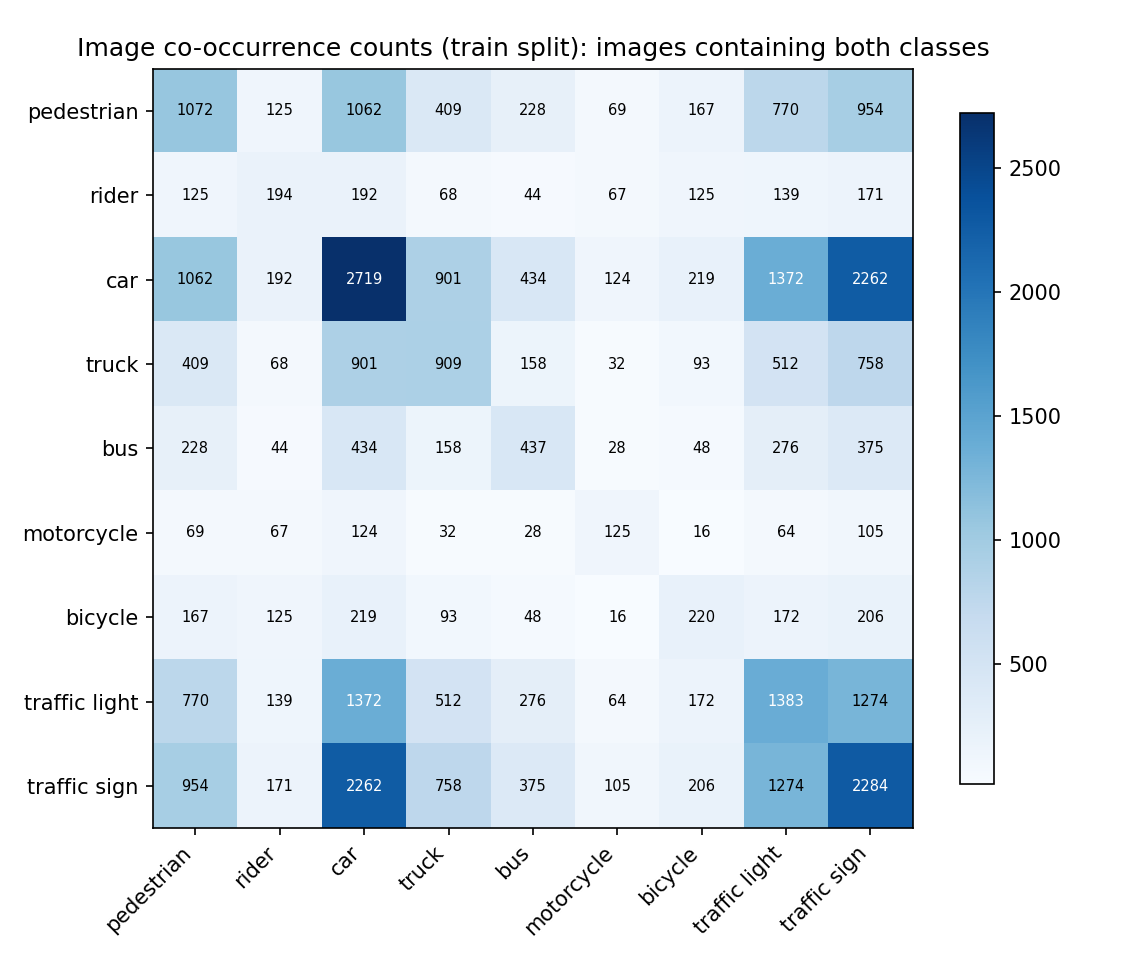

In [1]:
display(Image(filename=str(DA / 'class_cooccurrence.png')))

## 4. Rider heavily co-occurs with bicycle/motorcycle in the same image

Confirms the P0/error-cause-analysis finding: BDD100K annotates `rider` as only
the person, with the vehicle labeled separately -- so these three classes are
spatially and contextually entangled in the data itself, independent of anything
this project's pipeline does.

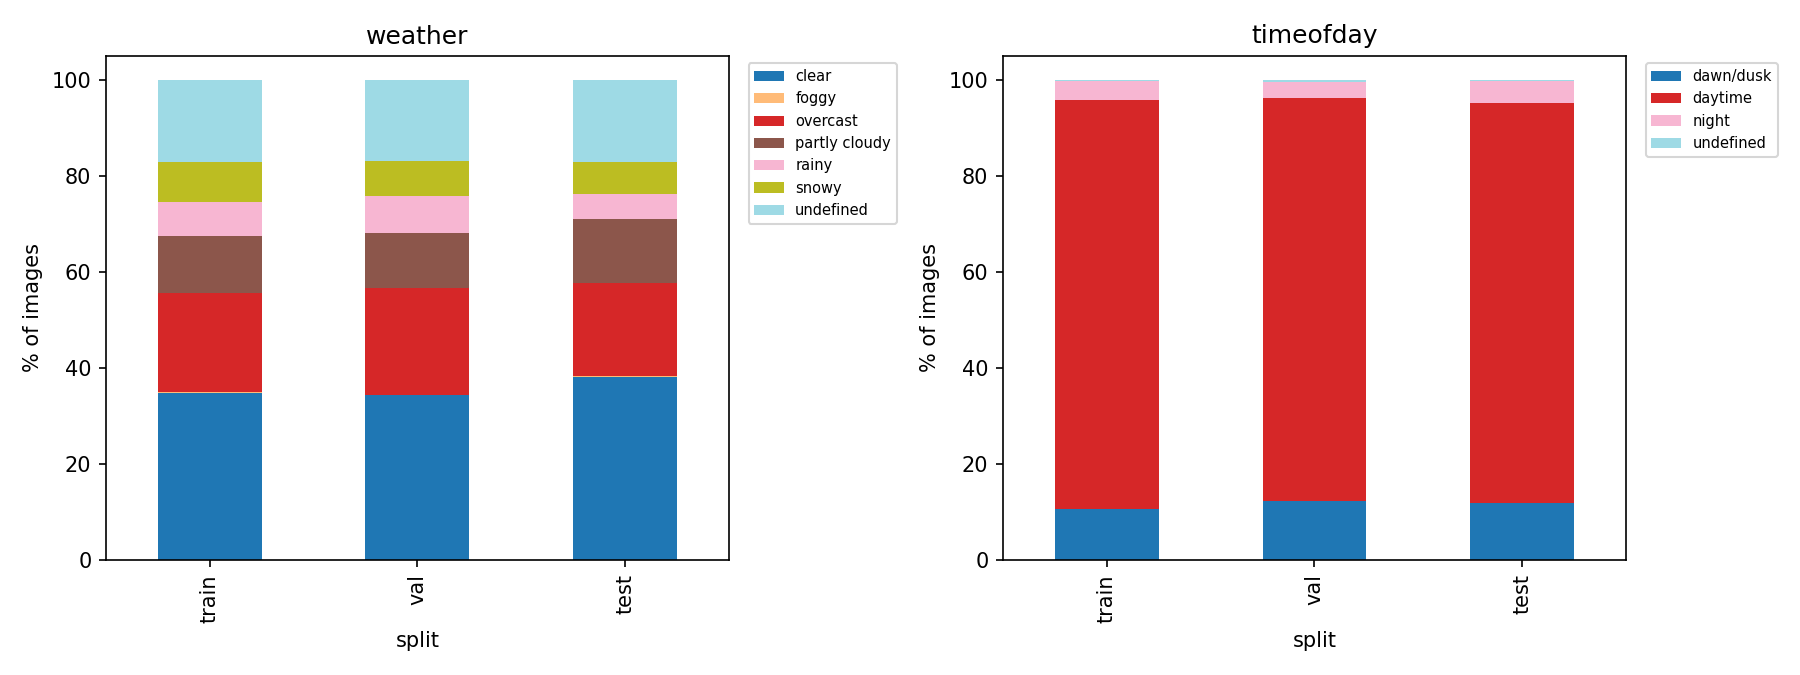

In [1]:
display(Image(filename=str(DA / 'image_attributes.png')))

## 5. Weather/time-of-day coverage is broad and consistent across splits

No split is skewed toward easier conditions -- train/val/test all cover a similar
mix of clear/overcast/rainy/snowy weather and daytime/night/dawn-dusk, consistent
with the earlier provenance finding that these are genuinely independent samples
of the same underlying BDD100K corpus.

## 6. Full BDD100K '100K images' package -- feasibility investigation (not downloaded)

The single highest-leverage fix for rare-class scarcity would be acquiring the
official 100K-image detection package to pair with the `labels/100k/*` files
already present locally (we have the labels; we're missing most of the images).
Per the approved V2 scope, this round **investigates feasibility only** -- no
download was attempted.

In [1]:
import subprocess, sys

print(subprocess.run([sys.executable, '../../scripts/drivesight_v2/check_full_dataset_feasibility.py'],

                      capture_output=True, text=True).stdout)

Local disk free: 8.8 GB of 480.3 GB total (checked at C:\)
  train: 70000 labels already present locally (vs 7000 images currently in the smaller 10K-images package)
  val: 10000 labels already present locally (vs 1000 images currently in the smaller 10K-images package)
  test: 20000 labels already present locally (vs 2000 images currently in the smaller 10K-images package)

Researched facts (not re-fetched by this script -- see module docstring):
  package: BDD100K official '100K images' detection package (70K train / 10K val / 20K test)
  mirror_with_direct_files: https://dl.cv.ethz.ch/bdd100k/data/ (ETH Zurich mirror)
  official_portal: https://bdd-data.berkeley.edu/download.html (TLS certificate currently EXPIRED as of this check -- browsers/tools will refuse to connect without an explicit override; use the ETHZ mirror instead)
  size_100k_images_train_zip: ~3.7 GB (70,000 train images)
  size_full_100k_package_all_splits: ~5.3 GB (train + val + test combined)
  registration_wall_o

**Conclusion**: the package itself is a bounded, well-identified ~5.3GB download
(70K-train-images zip alone is ~3.7GB) from a mirror with no apparent registration
wall (`dl.cv.ethz.ch/bdd100k/data/`; the official Berkeley portal's TLS
certificate is currently expired, a genuine access friction found during this
check) -- so technically feasible. But this machine currently has only **8.9GB of
free disk space**, which the download alone would consume most-to-all of.
**Decision: deferred to future work**, to be revisited after freeing up local
disk space. V2 proceeds on the existing 4,260-image dataset.

## Dataset readiness summary

- Split sizes, video-leakage, and label provenance are all independently
  verified and trustworthy (P0 diagnostics).
- Class imbalance (~121:1 car:rider) is real, severe, and consistent across
  splits -- `cls_pw` is a directly-targeted, already-verified-functional lever
  (notebook 04).
- Box size alone doesn't explain rider/motorcycle/bicycle's gap -- expect
  resolution (imgsz=1152, already validated in the V1 resolution ablation) to
  help broadly, and data/loss-weighting levers to matter specifically for the
  rare classes.
- More data (the full 100K package) remains the single highest-ceiling lever
  identified across this whole project, but is explicitly out of scope this
  round due to local disk constraints -- documented, not silently dropped.
- **V2 proceeds on the unchanged `data/bdd100k/yolo_dataset` split**
  (notebook 02 confirms this explicitly before any training).